In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
train_df = pd.read_csv('../DATA/datatraining.txt')
test_df1 = pd.read_csv('../DATA/datatest.txt')
test_df2 = pd.read_csv('../DATA/datatest2.txt')

In [3]:
train_df.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8143 entries, 1 to 8143
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           8143 non-null   object 
 1   Temperature    8143 non-null   float64
 2   Humidity       8143 non-null   float64
 3   Light          8143 non-null   float64
 4   CO2            8143 non-null   float64
 5   HumidityRatio  8143 non-null   float64
 6   Occupancy      8143 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 508.9+ KB


In [5]:
train_df = train_df.drop('date', axis=1)

In [6]:
test_df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2665 entries, 140 to 2804
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           2665 non-null   object 
 1   Temperature    2665 non-null   float64
 2   Humidity       2665 non-null   float64
 3   Light          2665 non-null   float64
 4   CO2            2665 non-null   float64
 5   HumidityRatio  2665 non-null   float64
 6   Occupancy      2665 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 166.6+ KB


In [7]:
test_df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9752 entries, 1 to 9752
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           9752 non-null   object 
 1   Temperature    9752 non-null   float64
 2   Humidity       9752 non-null   float64
 3   Light          9752 non-null   float64
 4   CO2            9752 non-null   float64
 5   HumidityRatio  9752 non-null   float64
 6   Occupancy      9752 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 609.5+ KB


In [8]:
test_df1 = test_df1.drop('date', axis=1)
test_df2 = test_df2.drop('date', axis=1)

In [9]:
test_df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2665 entries, 140 to 2804
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Temperature    2665 non-null   float64
 1   Humidity       2665 non-null   float64
 2   Light          2665 non-null   float64
 3   CO2            2665 non-null   float64
 4   HumidityRatio  2665 non-null   float64
 5   Occupancy      2665 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 145.7 KB


In [10]:
test_df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9752 entries, 1 to 9752
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Temperature    9752 non-null   float64
 1   Humidity       9752 non-null   float64
 2   Light          9752 non-null   float64
 3   CO2            9752 non-null   float64
 4   HumidityRatio  9752 non-null   float64
 5   Occupancy      9752 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 533.3 KB


In [11]:
train_df['Occupancy'].value_counts()

Occupancy
0    6414
1    1729
Name: count, dtype: int64

In [12]:
test_df1['Occupancy'].value_counts()

Occupancy
0    1693
1     972
Name: count, dtype: int64

In [13]:
test_df2['Occupancy'].value_counts()

Occupancy
0    7703
1    2049
Name: count, dtype: int64

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.impute import KNNImputer

In [15]:
X_train = train_df.drop('Occupancy', axis=1)
y_train = train_df['Occupancy']

In [16]:
X_test1 = test_df1.drop('Occupancy', axis=1)
y_test1 = test_df1['Occupancy']

In [17]:
X_test2 = test_df2.drop('Occupancy', axis=1)
y_test2 = test_df2['Occupancy']

In [18]:
num_features = X_train.select_dtypes(exclude='object').columns.tolist()

In [19]:
num_features

['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']

In [20]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [22]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler_2', StandardScaler()),
    ('model', LogisticRegressionCV(cv=10,
                                  penalty='l2',
                                  solver='lbfgs',
                                  Cs=10,
                                  max_iter=100_000,
                                  n_jobs=-1,
                                  random_state=104,
                                  class_weight='balanced'))
])

In [23]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)

In [24]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [25]:
y_pred_test1 = pipe.predict(X_test1)
y_pred_test2 = pipe.predict(X_test2)
y_pred_test1_proba = pipe.predict_proba(X_test1)[:, 1]
y_pred_test2_proba = pipe.predict_proba(X_test2)[:, 1]
y_train_proba = pipe.predict_proba(X_train)[:, 1]

In [26]:
accuracy_1 = accuracy_score(y_test1, y_pred_test1)
precision_1 = precision_score(y_test1, y_pred_test1)
recall_1 = recall_score(y_test1, y_pred_test1)
roc_auc_train = roc_auc_score(y_train, y_train_proba)
roc_auc_test_1 = roc_auc_score(y_test1, y_pred_test1_proba)

accuracy_2 = accuracy_score(y_test2, y_pred_test2)
precision_2 = precision_score(y_test2, y_pred_test2)
recall_2 = recall_score(y_test2, y_pred_test2)
roc_auc_test_2 = roc_auc_score(y_test2, y_pred_test2_proba)

In [27]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")
print(f"Лучшее значение l1_ratio: {best_model.l1_ratio_}")

Лучшее значение C: [0.04641589]
Лучшее значение l1_ratio: [None]


In [28]:
print(accuracy_1)
print(accuracy_2)

0.9789868667917448
0.9844134536505332


In [29]:
print(precision_1)
print(precision_2)

0.9463937621832359
0.9409576940957695


In [30]:
print(recall_1)
print(recall_2)

0.9989711934156379
0.9877989263055149


In [31]:
print(roc_auc_test_1)
print(roc_auc_test_2)

0.9916407186210954
0.9961934170653597


In [32]:
roc_auc_train

0.9948128037586952

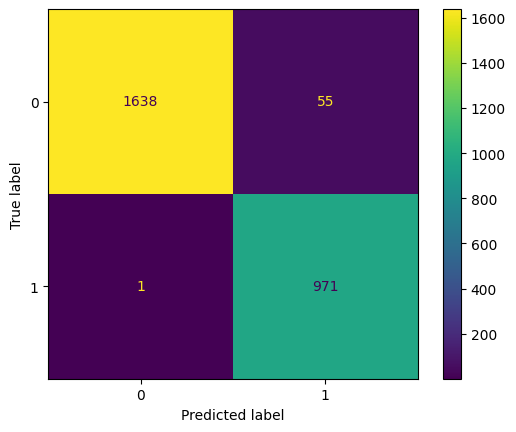

In [33]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test1, y_test1);

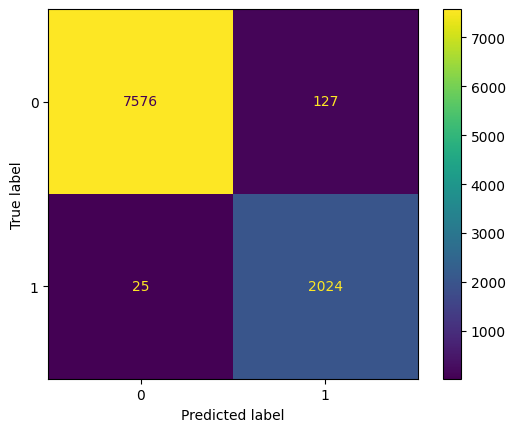

In [34]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test2, y_test2);

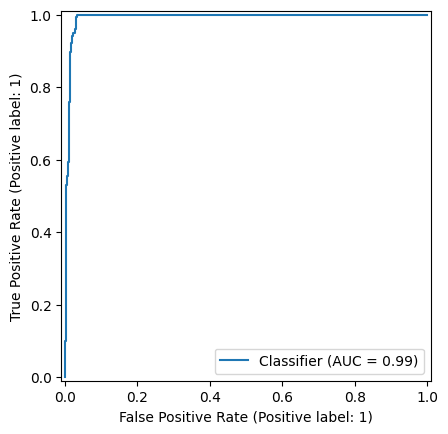

In [35]:
RocCurveDisplay.from_predictions(y_test1, y_pred_test1_proba);

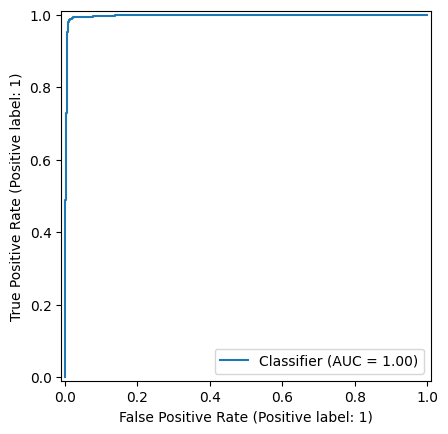

In [36]:
RocCurveDisplay.from_predictions(y_test2, y_pred_test2_proba);

In [37]:
df = pd.concat([train_df, test_df1, test_df2], axis=0, ignore_index=True)

In [38]:
df.duplicated().sum()

np.int64(1441)

In [39]:
df = df.drop_duplicates()

In [40]:
X = df.drop('Occupancy', axis=1)

In [41]:
y = df['Occupancy']

In [42]:
pipe.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers conta

In [43]:
y_pred_full_proba = pipe.predict_proba(X)[:, 1]

In [64]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")
print(f"Лучшее значение l1_ratio: {best_final_model.l1_ratio_}")

Лучшее значение C: [0.00599484]
Лучшее значение l1_ratio: [None]


In [45]:
roc_auc_full = roc_auc_score(y, y_pred_full_proba)

In [46]:
roc_auc_full

0.9941814658338713

In [47]:
accuracy = accuracy_2
precision = precision_1
recall = recall_1
roc_auc_test = roc_auc_test_2

In [48]:
accuracy

0.9844134536505332

In [49]:
precision

0.9463937621832359

In [50]:
recall

0.9989711934156379

In [51]:
roc_auc_test

0.9961934170653597

In [52]:
roc_auc_train

0.9948128037586952

In [53]:
test_df = pd.DataFrame([
    {
        'Temperature': 19.5,
        'Humidity': 23.2,
        'Light': 0.0,
        'CO2': 420.0,
        'HumidityRatio': 0.0033
    },
    {
        'Temperature': 24.1,
        'Humidity': 31.5,
        'Light': 520.0,
        'CO2': 1150.0,
        'HumidityRatio': 0.0058
    }
])

In [54]:
test_df

,Temperature,Humidity,Light,CO2,HumidityRatio
0,19.5,23.2,0.0,420.0,0.0033
1,24.1,31.5,520.0,1150.0,0.0058


In [55]:
probabilities = pipe.predict_proba(test_df)[:, 1]
predictions = pipe.predict(test_df)

In [56]:
print(f"--- Комната 1 (Пустая) -> Риск присутствия людей: {probabilities[0]:.2%}")
print(f"    Вердикт модели: Есть ли кто-то в комнате? -> {'ДА' if predictions[0] == 1 else 'НЕТ'}")

print(f"\n--- Комната 2 (Заселенная) -> Риск присутствия людей: {probabilities[1]:.2%}")
print(f"    Вердикт модели: Есть ли кто-то в комнате? -> {'ДА' if predictions[1] == 1 else 'НЕТ'}")

--- Комната 1 (Пустая) -> Риск присутствия людей: 1.71%
    Вердикт модели: Есть ли кто-то в комнате? -> НЕТ

--- Комната 2 (Заселенная) -> Риск присутствия людей: 99.71%
    Вердикт модели: Есть ли кто-то в комнате? -> ДА


In [57]:
class_percents = df['Occupancy'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%"
print(f"{baseline_string}")

0: 75.2%, 1: 24.8%


In [58]:
import json
import os

advanced_report = {
    "project": "Occupancy Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": precision,
        "Recall": recall,
        "ROC AUC Score Train": roc_auc_train,
        "ROC AUC Score Test": roc_auc_test,
        "ROC AUC Score Full": roc_auc_full,
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [59]:
from joblib import dump, load

In [60]:
dump(pipe, "model/occupancy_predict_logistic_regression_cv_2026_v1.pkl")

['model/occupancy_predict_logistic_regression_cv_2026_v1.pkl']

In [61]:
loaded_pipe = load("model/occupancy_predict_logistic_regression_cv_2026_v1.pkl")

In [62]:
loaded_pipe.predict(test_df)

array([0, 1])

In [63]:
loaded_pipe.predict_proba(test_df)[:, 1]

array([0.01711632, 0.997086  ])